## Практическое домашнее задание 1. Exploratory Data Analysis и линейная регрессия

### О задании
В этом задании мы попытаемся научиться анализировать данные и выделять из них полезные признаки. Мы также научимся пользоваться `seaborn` и `sklearn`, а заодно привыкнем к основным понятиям машинного обучения.

Задание было адаптировано из курса по машинному обучению Е.А. Соколова.

### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу - 5 баллов. Помимо концептуальных ошибок и отсутствия решения, оценка может быть снижена за неэффективную реализацию или неопрятные графики.

**Обратите внимание**, что в каждом разделе домашнего задания есть оцениваемые задачи и есть вопросы. Вопросы дополняют задачи и направлены на то, чтобы проинтерпретировать или обосновать происходящее. Код без интерпретации не имеет смысла, поэтому отвечать на вопросы обязательно - за отсутствие ответов баллы будут снижены. Если вы ответите на вопросы, но не напишете корректный код к соответствующим оцениваемым задачам, то баллы за такое выставлены не будут.

### Формат сдачи
Задания сдаются через ваш приватный гит репозиторий. Туда необходимо сложить только ноутбук с вашим решением. 

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

Оценка: xx.

**Ответ**: **5/5 баллов**

В этом задании используется библиотека `folium` для визуализации карт. Установим ее.

Она работает и в google colab.

In [95]:
# Сразу все качаем и проверяем что проросло в ноутбук:
# pip install numpy pandas matplotlib seaborn scikit-learn folium
import importlib.metadata as metadata
print({p: metadata.version(p) for p in ['numpy','pandas','matplotlib','seaborn','scikit-learn','folium']})

{'numpy': '2.5.3', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'scikit-learn': '1.9.1', 'folium': '0.20.0'}


In [96]:
import folium

m = folium.Map(location=(55.7522200, 37.6155600), zoom_start=10)

m

Если вы всё сделали правильно, то выше должна открыться карта Москвы.

In [97]:
# Подготовка всех либ - бойлерплейт
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
%matplotlib inline
sns.set_theme(style='darkgrid', font='DejaVu Sans', rc={'figure.figsize': (11, 4)})
SEED = 42
TARGET = 'log_trip_duration'
results = []
def rmse(y, pred):
    return root_mean_squared_error(y, pred)
def report(name, model, train, test):
    train_pred = model.predict(train)
    test_pred = model.predict(test)
    assert np.isfinite(test_pred).all()
    results.append({'этап': name, 'train RMSE': rmse(train[TARGET], train_pred),
                    'test RMSE': rmse(test[TARGET], test_pred)})
    display(pd.DataFrame(results).round(5))
    return test_pred

## Часть 0. Подготовка (0.5 балла)

**Задание 1**. Мы будем работать с данными из соревнования [New York City Taxi Trip Duration](https://www.kaggle.com/c/nyc-taxi-trip-duration/overview), в котором нужно было предсказать длительность поездки на такси. Скачайте **обучающую** выборку из этого соревнования и загрузите ее. Там же вы можете найти и описание полей. Переменную с датасетом лучше назвать `df`.

In [98]:
DATA_PATH = Path('data/train.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Файла нет')
df = pd.read_csv(DATA_PATH)
assert len(df) == 1_458_644, 'Маленькая выборка'
assert df['id'].is_unique and df['trip_duration'].gt(0).all()
print('Размер выборки:', df.shape)
display(df.head())

Размер выборки: (1458644, 11)


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


Обратите внимание на колонки `pickup_datetime` и `dropoff_datetime`. `dropoff_datetime` была добавлена организаторами только в обучающую выборку, то есть использовать эту колонку нельзя, давайте удалим ее. В `pickup_datetime` записаны дата и время начала поездки. Чтобы с ней было удобно работать, давайте преобразуем даты в `datetime`-объекты

In [99]:
df = df.drop(columns='dropoff_datetime')
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

Проведите стандартные проверки датасета:
- Типы полей
- Пропущенные значения
- Дубликаты

Никаких операций (даже если что-то обнаружится) пока проводить не нужно.

In [100]:
display(pd.DataFrame({'тип': df.dtypes.astype(str), 'пропуски': df.isna().sum()}))
print('Дубликатов:', df.duplicated().sum())

,тип,пропуски
id,str,0
vendor_id,int64,0
pickup_datetime,datetime64[us],0
passenger_count,int64,0
pickup_longitude,float64,0
pickup_latitude,float64,0
dropoff_longitude,float64,0
dropoff_latitude,float64,0
store_and_fwd_flag,str,0
trip_duration,int64,0


Дубликатов: 0


В колонке `trip_duration` записано целевое значение, которое мы хотим предсказывать. Давайте посмотрим на распределение таргета в обучающей выборке. Для этого нарисуйте его гистограмму:

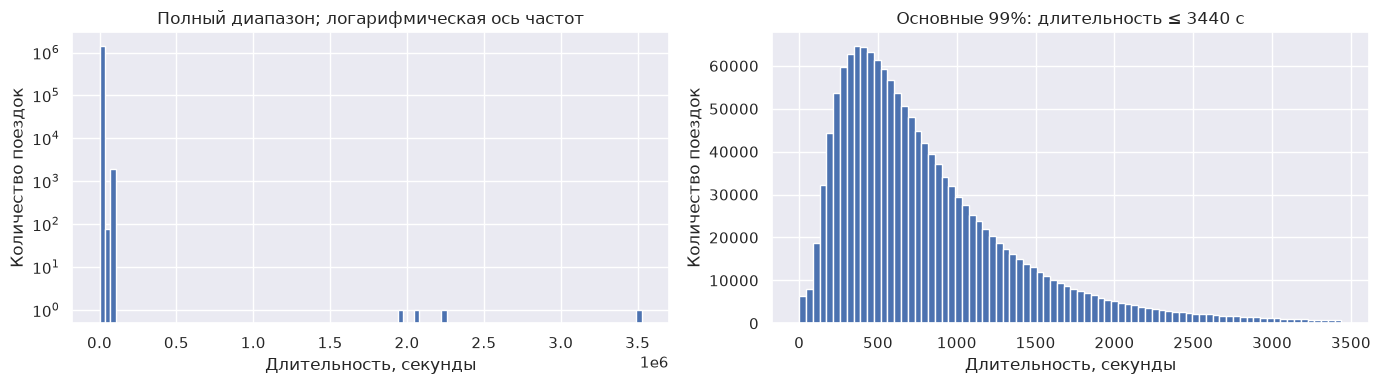

Вне правого графика: 14575 поездок (1.00%). Данные не поместились на график


count    1.458644e+06
mean     9.594923e+02
std      5.237432e+03
min      1.000000e+00
50%      6.620000e+02
90%      1.634000e+03
99%      3.440000e+03
99.9%    8.512836e+04
max      3.526282e+06
Name: trip_duration, dtype: float64

In [101]:
limit = df.trip_duration.quantile(.99)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df.trip_duration, bins=100)
axes[0].set(yscale='log', title='Полный диапазон; логарифмическая ось частот', xlabel='Длительность, секунды', ylabel='Количество поездок')
axes[1].hist(df.loc[df.trip_duration <= limit, 'trip_duration'], bins=80)
axes[1].set(title=f'Основные 99%: длительность ≤ {limit:.0f} с', xlabel='Длительность, секунды', ylabel='Количество поездок')
plt.tight_layout(); plt.show()
print(f'Вне правого графика: {(df.trip_duration > limit).sum()} поездок ({(df.trip_duration > limit).mean():.2%}). Данные не поместились на график')
display(df.trip_duration.describe(percentiles=[.5,.9,.99,.999]))

**Вопрос**: Что можно сказать о целевой переменной по гистограмме её значений?

**Ответ**: Распределение сильно скошено вправо. основная масса поездок короткая, но есть очень длинный хвост, вплоть до нескольких недель (если их нарисовать, тогда левую короткую часть не будет видно, хотя основая часть поездок находится в 0-3440с). справа отдельно показаны 99% наблюдений. Большие значения требуют исследования (то есть не забыть что они есть)

В соревновании в качестве метрики качества использовалось RMSLE:
$$\text{RMSLE}(X, y, a) = \sqrt{\frac{1}{\ell}\sum_{i=1}^{\ell} \big(\log{(y_i + 1)} - \log{(a(x_i) + 1)}\big)^2}$$

**Вопрос**: Как вы думаете, почему авторы соревнования выбрали именно RMSLE, а не RMSE?

**Ответ** RMSE в секундах сильно зависит от единичных очень длинных поездок. RMSLE сравнивает логарифмы. То есть промах на 10 минут для короткой и многочасовой поездки имеет разное значение

Мы рассматривали модели линейной регрессии в `sklearn`, но каждая из них оптимизировала среднеквадратичную ошибку (MSE), а не RMSLE. Давайте проделаем следующий трюк: будем предсказывать не целевую переменную, а ее *логарифм*. Обозначим $\hat{y}_i = \log{(y_i + 1)}$ - модифицированный таргет, а $\hat{a}(x_i)$ - предсказание модели, которая обучалась на $\hat{y}_i$, то есть логарифм таргета. Чтобы предсказать исходное значение, мы можем просто взять экспоненту от нашего предсказания: $a(x_i) = \exp(\hat{a}(x_i)) - 1$.

**Вопрос**: Покажите, что оптимизация RMSLE для модели $a$ эквивалентна оптимизации MSE для модели $\hat{a}$.

**Ответ** Подставим $a(x)=\exp(\hat a(x))-1$: тогда $\log(1+a(x))=\hat a(x)$ и $\mathrm{RMSLE}=\sqrt{\frac1l\sum_i(\hat y_i-\hat a(x_i))^2}=\sqrt{\mathrm{MSE}_{log}}$

Итак, мы смогли свести задачу оптимизации RMSLE к задаче оптимизации MSE, которую мы умеем решать! Кроме того, у логарифмирования таргета есть еще одно полезное свойство. Чтобы его увидеть, добавьте к нашей выборке колонку `log_trip_duration` (воспользуйтесь `np.log1p`) и нарисуйте гистограмму модифицированного таргета по обучающей выборке. Удалите колонку со старым таргетом.

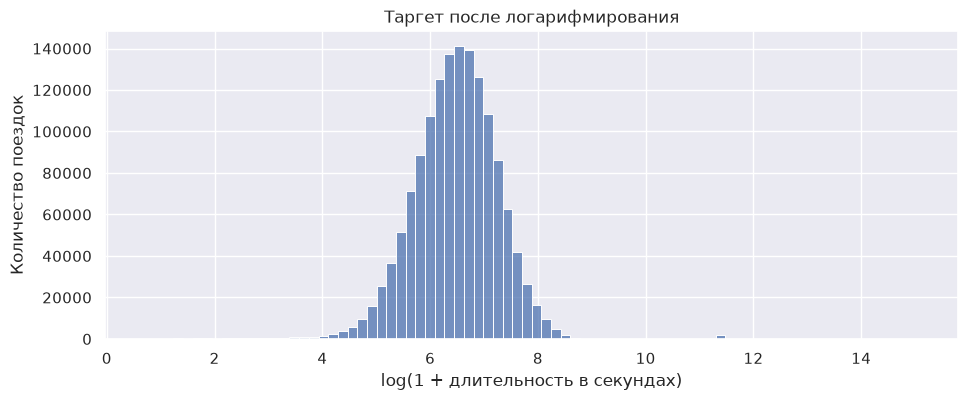

In [102]:
df[TARGET] = np.log1p(df.trip_duration)
df = df.drop(columns='trip_duration')
sns.histplot(df[TARGET], bins=80)
plt.xlabel('log(1 + длительность в секундах)'); plt.ylabel('Количество поездок'); plt.title('Таргет после логарифмирования'); plt.show()

Чтобы иметь некоторую точку отсчета, давайте посчитаем значение метрики при наилучшем константном предсказании. Что здесь будет соответствовать лучшему константному предсказанию?

In [103]:
constant_all = df[TARGET].mean()
print(f'Оптимальная константа в лог-шкале: {constant_all:.5f}; в секундах: {np.expm1(constant_all):.1f}')
print(f'Описательный RMSE на всей выборке: {rmse(df[TARGET], np.full(len(df), constant_all)):.5f}')

Оптимальная константа в лог-шкале: 6.46698; в секундах: 642.5
Описательный RMSE на всей выборке: 0.79576


**Ответ** Для квадратичной ошибки оптимум - среднее логарифма таргета: производная $\sum_i(z_i-c)^2$ по $c$ равна нулю при $c=\bar z$. В исходной шкале это $\exp(\overline{\log(1+y)})-1$ (потому что работаем с логарифмами, а не линейным случаем)

## Часть 1. Изучаем `pickup_datetime` (1 балл)

**Задание 2**. Для начала давайте посмотрим, сколько всего было поездок в каждый из дней. Постройте график зависимости количества поездок от дня в году (например, можно воспользоваться `sns.countplot`):

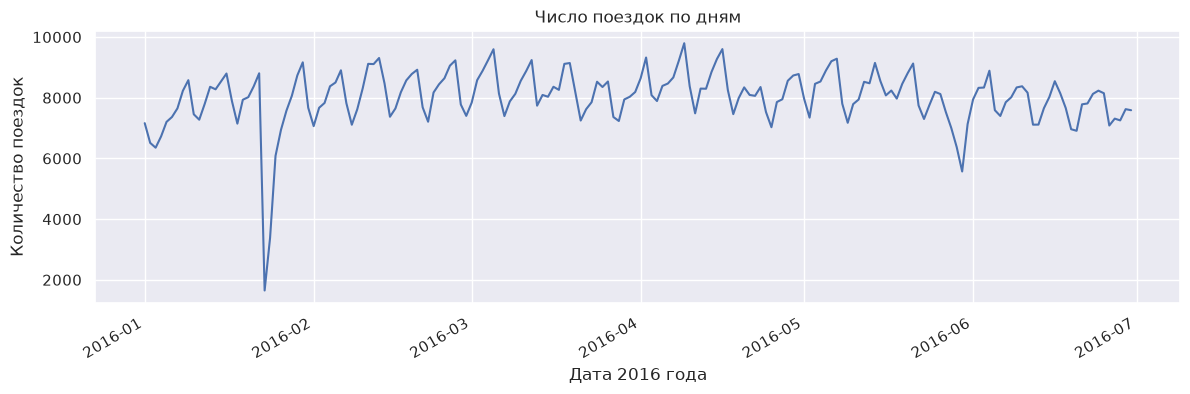

In [104]:
daily = df.groupby(df.pickup_datetime.dt.normalize()).size().rename('поездки')
fig, ax = plt.subplots(figsize=(14,4))
ax.plot(daily.index, daily.values)
ax.set(xlabel='Дата 2016 года', ylabel='Количество поездок', title='Число поездок по дням')
fig.autofmt_xdate(); plt.show()

**Вопрос**: Вы, вероятно, заметили, что на графике есть 2 периода с аномально маленькими количествами поездок. Вычислите, в какие даты происходили эти скачки вниз и найдите информацию о том, что происходило в эти дни в Нью-Йорке.

In [105]:
display(daily.nsmallest(12).to_frame())

,поездки
pickup_datetime,
2016-01-23,1648
2016-01-24,3383
2016-05-30,5570
2016-01-25,6084
2016-01-03,6353
2016-05-29,6372
2016-01-02,6512
2016-01-04,6725
2016-06-20,6910


**Ответ**: 23–24 января и конец мая в частности 30 мая

23 января - снежная буря. город вводил ограничения движения (= Снег непосредственно мешал движению)

В конце мая - длинные выходные Memorial Day (30 мая 2016 года) (= отъезд жителей и изменение рабочих поездок в праздник) 

Но вывод я б тут не делал - 1 факта про снег и праздник мало для объяснения, а более я не нашел. возможно если сильнее покопать можно лучше объяснить, но кажется задание подразумевает примерно такой ответ 

Нарисуйте графики зависимости количества поездок от дня недели и от часов в сутках (воспользуйтесь `sns.relplot`):

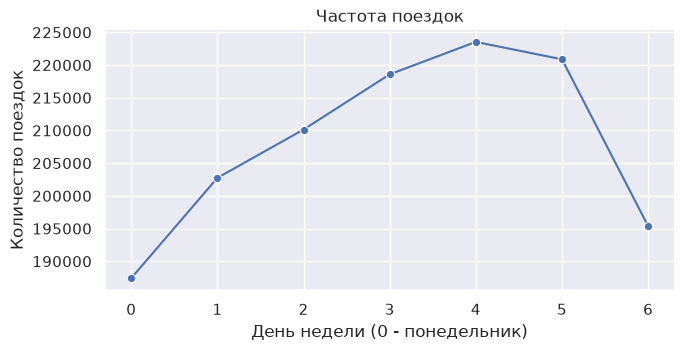

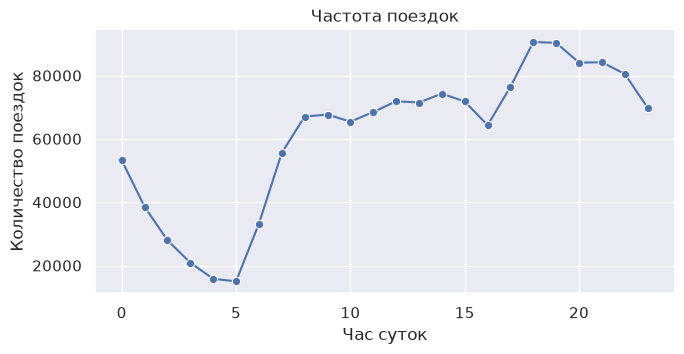

In [106]:
calendar = pd.DataFrame({'weekday': df.pickup_datetime.dt.dayofweek, 'hour': df.pickup_datetime.dt.hour, 'month': df.pickup_datetime.dt.month})
for col, label in [('weekday','День недели (0 - понедельник)'), ('hour','Час суток')]:
    counts = calendar.groupby(col).size().rename('Количество поездок').reset_index()
    g = sns.relplot(data=counts, x=col, y='Количество поездок', kind='line', marker='o', height=3.5, aspect=2)
    g.set_axis_labels(label, 'Количество поездок'); g.ax.set_title('Частота поездок'); plt.show()

**Задание 3**. Нарисуйте на одном графике зависимости количества поездок от часа в сутках для разных месяцев (разные кривые, соответствующие разным месяцам, окрашивайте в разные цвета, воспользуйтесь `hue` в `sns.relplot`). Аналогично нарисуйте зависимости количества поездок от часа в сутках для разных дней недели.

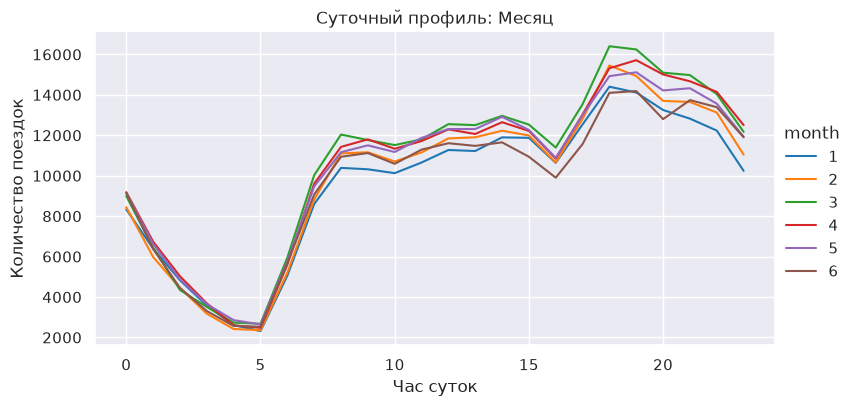

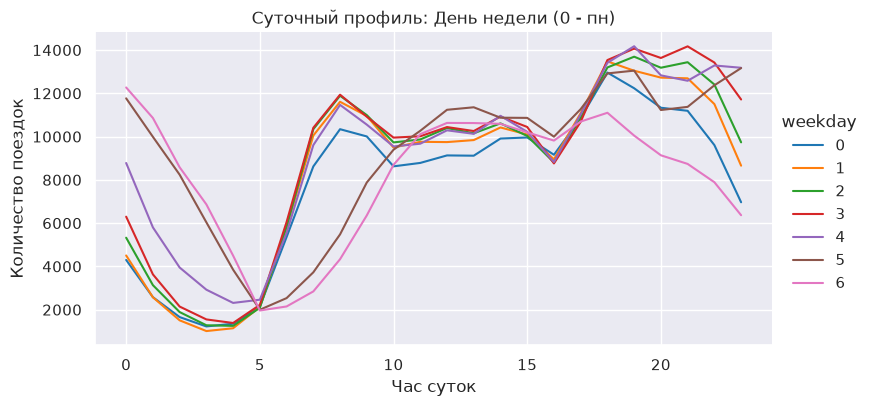

Не учитывал разное количество дней в месяце (= не нормировал)


In [107]:
for col, label in [('month','Месяц'), ('weekday','День недели (0 - пн)')]:
    counts = calendar.groupby([col,'hour']).size().rename('Количество поездок').reset_index()
    g = sns.relplot(data=counts, x='hour', y='Количество поездок', hue=col, palette='tab10', kind='line', height=4, aspect=2)
    g.set_axis_labels('Час суток', 'Количество поездок'); g.ax.set_title(f'Суточный профиль: {label}'); plt.show()
print('Не учитывал разное количество дней в месяце (= не нормировал)')

**Вопрос**: Какие выводы можно сделать, основываясь на графиках выше? Выделяются ли какие-нибудь дни недели? Месяца? Время суток? С чем это связано?

**Ответ** 
Ранним утром поездок меньше, вечером спрос увеличивается

Выходные отличаются более активной ночью и более поздним утренним ростом

В январе–марте максимум наблюдается в 18:00, в апреле–июне - в 19:00 (летнее время как раз, со второго вскр марта - отметил про нормализацию)

Различия между месяцами включают сезонность и число дней в месяце, поэтому абсолютные количества нельзя оценивать как эффект от чего-то одного (к вопросу про нормализацию)

**Задание 4**. Разбейте выборку на обучающую и тестовую в отношении 7:3. По обучающей выборке нарисуйте график зависимости среднего логарифма времени поездки от дня недели. Затем сделайте то же самое, но для часа в сутках и дня в году.

,этап,train RMSE,test RMSE
0,Константа (среднее train),0.796073,0.795027


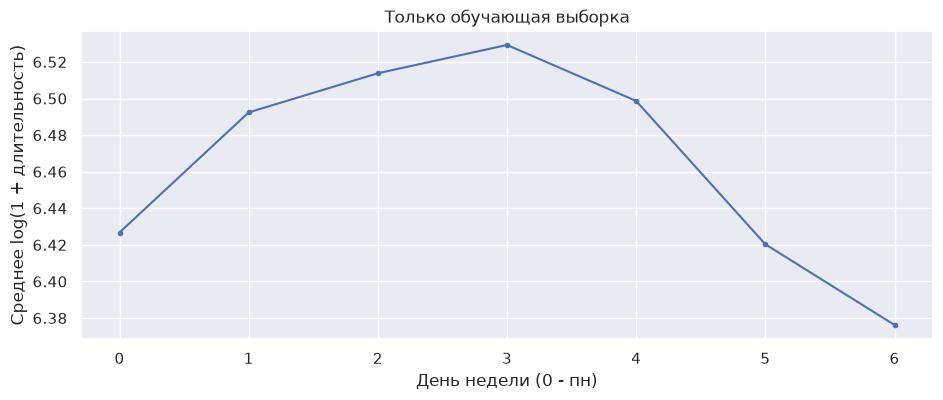

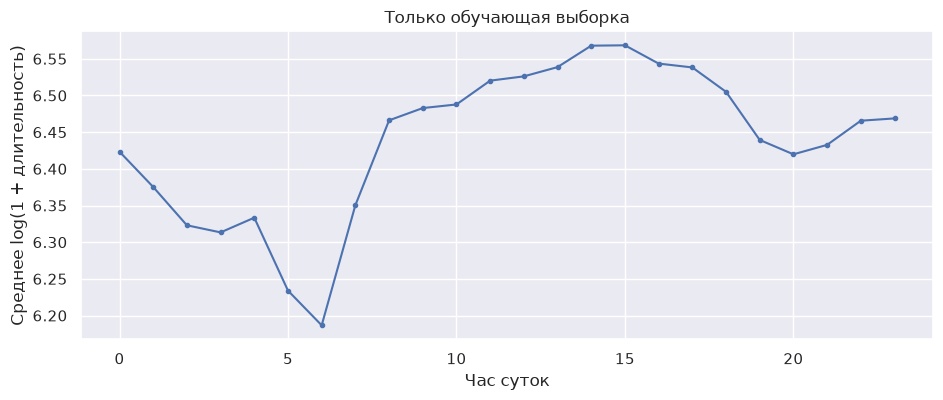

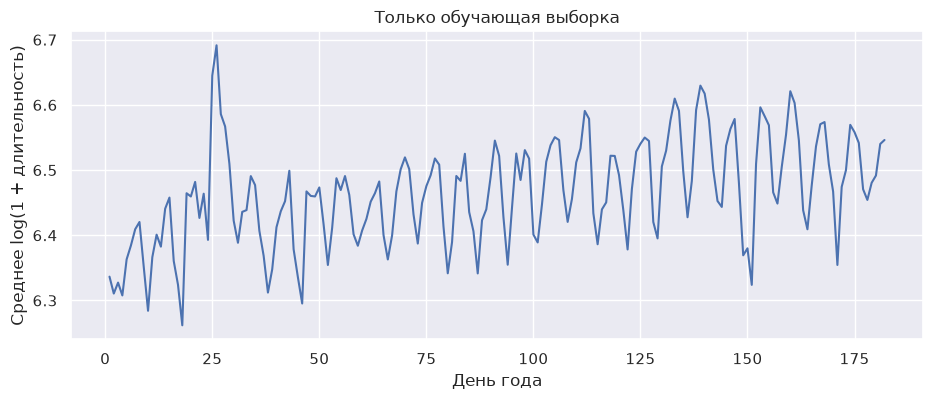

date
2016-01-20    6.459521
2016-01-21    6.481895
2016-01-22    6.426626
2016-01-23    6.463779
2016-01-24    6.392959
2016-01-25    6.644804
2016-01-26    6.691444
2016-01-27    6.585878
2016-01-28    6.567003
Name: log_trip_duration, dtype: float64

In [108]:
train, test = train_test_split(df, test_size=.3, random_state=SEED)
train, test = train.copy(), test.copy()
assert train.index.intersection(test.index).empty
constant = train[TARGET].mean()
results.append({'этап':'Константа (среднее train)', 'train RMSE':rmse(train[TARGET], np.full(len(train),constant)), 'test RMSE':rmse(test[TARGET],np.full(len(test),constant))})
display(pd.DataFrame(results))
for key, label in [('dayofweek','День недели (0 - пн)'), ('hour','Час суток'), ('dayofyear','День года')]:
    means = train.groupby(getattr(train.pickup_datetime.dt,key))[TARGET].mean()
    means.plot(marker='.' if key!='dayofyear' else None)
    plt.xlabel(label); plt.ylabel('Среднее log(1 + длительность)'); plt.title('Только обучающая выборка'); plt.show()
period = train.pickup_datetime.dt.normalize()
display(train.assign(date=period).groupby('date')[TARGET].mean().loc['2016-01-20':'2016-01-28'])

**Вопрос**: Похожи ли графики зависимости таргета от дня недели и от часа в сутках на аналогичные графики для количества поездок? Почему? Что происходит со средним таргетом в те два аномальных периода, что мы видели выше? Почему так происходит? Наблюдаете ли вы какой-нибудь тренд на графике зависимости `log_trip_duration` от номера дня в году?

Чтобы разобраться, скорее всего придется поискать, что происходило в Нью-Йорке во второй половине января 2016.

**Ответ** В рабочие часы заторы увеличивают время даже при сравнительно небольшом количестве стартующих поездок. 23–24 января количество поездок резко падает

Самый выраженный рост среднего лог-таргета виден 25–26 января (6.645 и 6.691), после метели. возможное объяснение - последствия снегопада при возобновлении рабочих поездок

В майские выходные среднее снижается: с 6.578 26 мая до 6.324 30 мая, что согласуется с более свободными дорогами

Добавьте следующие признаки на основе `pickup_datetime`:
1. День недели
2. Месяц
3. Час
4. Является ли период аномальным (два бинарных признака, соответствующие двум аномальным периодам)
5. Номер дня в году

In [109]:
def time_features(data):
    out = data.copy()
    dt = out.pickup_datetime.dt
    out['weekday'], out['month'], out['hour'], out['dayofyear'] = dt.dayofweek, dt.month, dt.hour, dt.dayofyear
    day = out.pickup_datetime.dt.normalize()
    out['snow'] = day.between('2016-01-23','2016-01-24').astype(int)
    out['memorial'] = day.between('2016-05-28','2016-05-30').astype(int)
    return out
train, test = time_features(train), time_features(test)
time_cat = ['weekday','month','hour','snow','memorial']
time_num = ['dayofyear']

Итак, мы уже создали некоторое количество признаков.

**Вопрос**: Какие из признаков стоит рассматривать как категориальные, а какие - как числовые? Почему?

**Ответ** День недели, месяц и час - категориальные: эффект не обязан линейно расти с номером. 'snow', 'memorial' - бинарные категории. День года - числовой признак для плавного временного тренда. Дату и id в модель не передаём

**Задание 5**. Обучите `Ridge`-регрессию с параметрами по умолчанию, закодировав все категориальные признаки с помощью `OneHotEncoder`. Численные признаки отмасштабируйте с помощью `StandardScaler`. Используйте только признаки, которые мы выделили в этой части задания.

In [110]:
def make_model(categorical, numerical, estimator=None, min_frequency=None):
    prep = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist' if min_frequency else 'ignore', min_frequency=min_frequency), categorical),
        ('num', StandardScaler(), numerical)
    ], sparse_threshold=1.0)
    return Pipeline([('preprocess',prep), ('model', Ridge() if estimator is None else estimator)])
time_model = make_model(time_cat,time_num)
time_model.fit(train,train[TARGET])
_ = report('Часть 1: время',time_model,train,test)

,этап,train RMSE,test RMSE
0,Константа (среднее train),0.79607,0.79503
1,Часть 1: время,0.78905,0.78813


## Часть 2. Изучаем координаты (1.5 балла)
Мы уже очень хорошо изучили данные о времени начала поездки, давайте теперь посмотрим на информацию о координатах начала и конца поездки. Для вас подготовлена функция, которая на карте рисует точки начала или конца поездки. Примеры ее вызова вы найдете ниже. Обратите внимание, что в эту функцию лучше передавать лишь небольшой кусочек данных, поскольку иначе она будет работать очень долго

In [111]:
def show_circles_on_map(data, latitude_column, longitude_column, color):
    """
    The function draws map with circles on it.
    The center of the map is the mean of coordinates passed in data.
    
    data: DataFrame that contains columns latitude_column and longitude_column
    latitude_column: string, the name of column for latitude coordinates
    longitude_column: string, the name of column for longitude coordinates
    color: string, the color of circles to be drawn
    """

    location = (data[latitude_column].mean(), data[longitude_column].mean())
    m = folium.Map(location=location)

    for _, row in data.iterrows():
        folium.Circle(
            radius=100,
            location=(row[latitude_column], row[longitude_column]),
            color=color,
            fill_color=color,
            fill=True
        ).add_to(m)

    return m

In [112]:
show_circles_on_map(df.sample(1000, random_state=SEED), 'pickup_latitude', 'pickup_longitude', 'blue')

In [113]:
show_circles_on_map(df.sample(1000, random_state=SEED), 'dropoff_latitude', 'dropoff_longitude', 'blue')

**Вопрос**: Какие две точки выделяются на карте?

**Ответ** аэропорты JFK и LaGuardia

**Задание 6**. Как мы все прекрасно помним, $t = s / v_{\text{ср}}$, поэтому очевидно, что самым сильным признаком будет расстояние, которое необходимо проехать. Мы не можем посчитать точное расстояние, которое необходимо преодолеть такси, но мы можем его оценить, посчитав кратчайшее расстояние между точками начала и конца поездки. Чтобы корректно посчитать расстояние между двумя точками на Земле, можно использовать функцию `haversine`. Реализация функции представлена ниже. Посчитайте кратчайшее расстояние для объектов и запишите его в колонку `haversine`:

In [114]:
def haversine_array(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    AVG_EARTH_RADIUS = 6371 
    lat = lat2 - lat1
    lng = lng2 - lng1
    d = np.sin(lat * 0.5) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(lng * 0.5) ** 2
    h = 2 * AVG_EARTH_RADIUS * np.arcsin(np.sqrt(d))
    return h

In [115]:
for data in [train,test]:
    data['haversine'] = haversine_array(data.pickup_latitude,data.pickup_longitude,data.dropoff_latitude,data.dropoff_longitude)
assert np.isclose(haversine_array(40.,-74.,40.,-74.),0.)

Так как мы предсказываем логарифм времени поездки и хотим, чтобы наши признаки были линейно зависимы с этой целевой переменной, нам нужно логарифмировать расстояние: $\log t = \log s - \log{v_{\text{ср}}}$. Запишите логарифм `haversine` в отдельную колонку:

In [116]:
for data in [train,test]:
    data['log_haversine'] = np.log(np.maximum(data.haversine, .001))
assert np.isfinite(train.log_haversine).all()
print('Расстояние в км; для логарифма нижняя граница 0.001 км (1 метр), чтобы обработать совпадающие координаты.')

Расстояние в км; для логарифма нижняя граница 0.001 км (1 метр), чтобы обработать совпадающие координаты.


Убедимся, что логарифм расстояния лучше коррелирует с нашим таргетом, чем просто расстояние:

In [117]:
display(train[['haversine','log_haversine',TARGET]].corr())

,haversine,log_haversine,log_trip_duration
haversine,1.000000,0.675611,0.565406
log_haversine,0.675611,1.000000,0.722878
log_trip_duration,0.565406,0.722878,1.000000


**Задание 7**. Давайте изучим среднюю скорость движения такси. Посчитайте среднюю скорость для каждого объекта обучающей выборки, разделив `haversine` на `trip_duration`, и нарисуйте гистограмму ее распределения

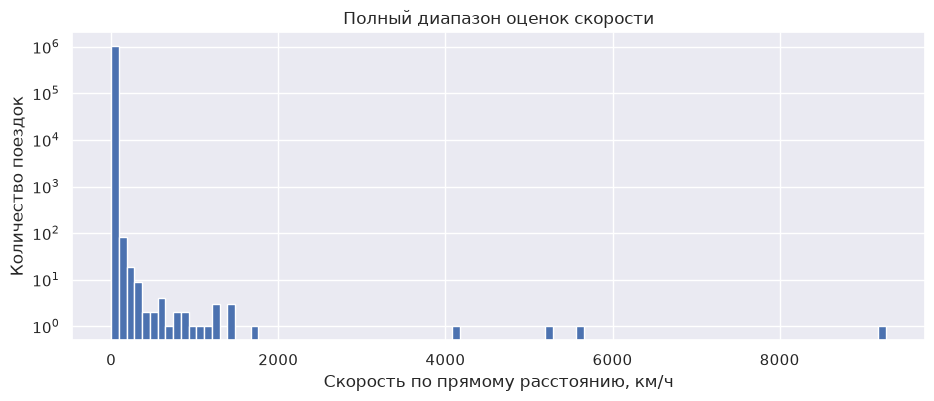

In [118]:
speed = train.haversine / np.expm1(train[TARGET]) * 3600
plt.hist(speed, bins=100); plt.yscale('log'); plt.xlabel('Скорость по прямому расстоянию, км/ч'); plt.ylabel('Количество поездок'); plt.title('Полный диапазон оценок скорости'); plt.show()

Как можно видеть по гистограмме, для некоторых объектов у нас получились очень большие значения скоростей. Нарисуйте гистограмму по объектам, для которых значение скорости получилось разумным (например, можно не включать в рассмотрение объекты, где скорость больше некоторой квантили):

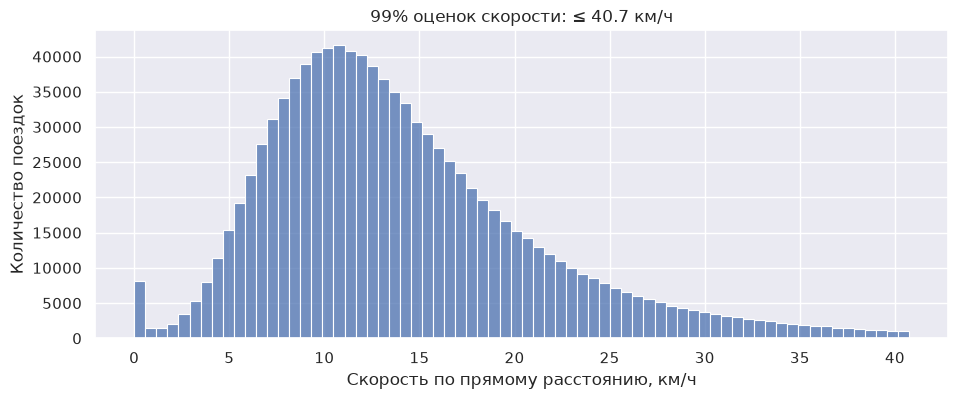

In [119]:
speed_limit = speed.quantile(.99)
sns.histplot(speed[speed <= speed_limit], bins=70)
plt.xlabel('Скорость по прямому расстоянию, км/ч'); plt.ylabel('Количество поездок'); plt.title(f'99% оценок скорости: ≤ {speed_limit:.1f} км/ч'); plt.show()

Для каждой пары (день недели, час суток) посчитайте медиану скоростей. Нарисуйте с помощью `sns.heatmap` график, где по осям будут дни недели и часы, а в качестве значения функции - медиана скорости

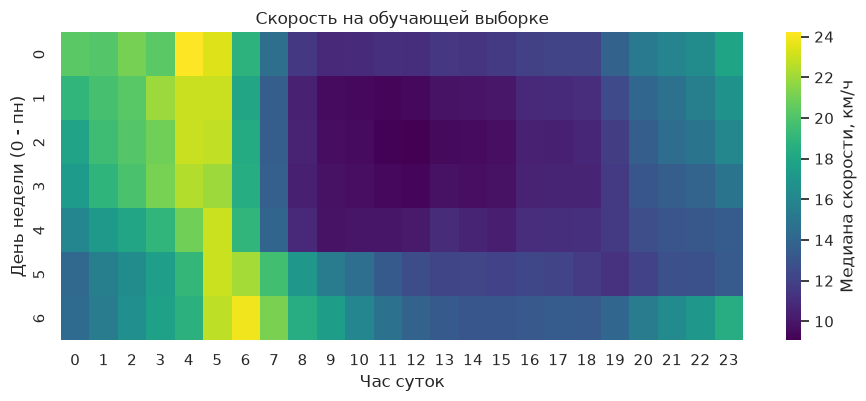

Минимум: Среда, 12:00 — 9.07 км/ч
Максимум: Понедельник, 04:00 — 24.22 км/ч


In [120]:
speed_table = train.assign(speed=speed).pivot_table(index='weekday',columns='hour',values='speed',aggfunc='median')
sns.heatmap(speed_table,cmap='viridis',cbar_kws={'label':'Медиана скорости, км/ч'})
plt.xlabel('Час суток'); plt.ylabel('День недели (0 - пн)'); plt.title('Скорость на обучающей выборке'); plt.show()

days = ['Понедельник', 'Вторник', 'Среда', 'Четверг', 'Пятница', 'Суббота', 'Воскресенье']

for label, pair in [
    ('Минимум', speed_table.stack().idxmin()),
    ('Максимум', speed_table.stack().idxmax()),
]:
    day, hour = pair
    value = speed_table.loc[day, hour]
    print(f'{label}: {days[day]}, {hour:02d}:00 — {value:.2f} км/ч')

Не забудьте удалить колонку со значением скорости из данных!

**Вопрос**: Почему значение скорости нельзя использовать во время обучения?

**Ответ** Скорость вычислена через истинную длительность, которую мы пытаемся предсказать: это утечка таргета

**Вопрос**: Посмотрите внимательно на график и скажите, в какие моменты времени скорость минимальна; максимальна.

**Ответ** 

Минимум: Среда, 12:00 — 9.07 км/ч
Максимум: Понедельник, 04:00 — 24.22 км/ч


Создайте признаки "поездка совершается в период пробок" и "поездка совершается в период свободных дорог" (естественно, они не должны зависеть от скорости!):

In [121]:
def traffic_features(data):
    out = data.copy()
    out['traffic'] = ((out.weekday < 5) & out.hour.between(8,19)).astype(int)
    out['free_roads'] = out.hour.between(2,5).astype(int)
    return out
train, test = traffic_features(train), traffic_features(test)

**Задание 8**. Как уже было замечено выше, на карте выделяются две точки вдали от Манхэттена. Для каждой из них добавьте в выборку два признака: началась ли поездка в ней и закончилась ли она в ней.

In [122]:
AIRPORT_RADIUS = 2
airport_cols = []
for name, lat, lon in [('JFK',40.6413,-73.7781),('LGA',40.7769,-73.8740)]:
    for end in ['pickup','dropoff']:
        col = end+'_'+name
        airport_cols.append(col)
        for data in [train,test]:
            data[col] = (haversine_array(data[end+'_latitude'],data[end+'_longitude'],lat,lon) <= AIRPORT_RADIUS).astype(int)
print(f'Окрестность каждого аэропорта - радиус {AIRPORT_RADIUS} км.')

Окрестность каждого аэропорта - радиус 2 км.


Для каждого из созданных признаков нарисуйте "ящик с усами" (`sns.boxplot`) распределения логарифма времени поездки

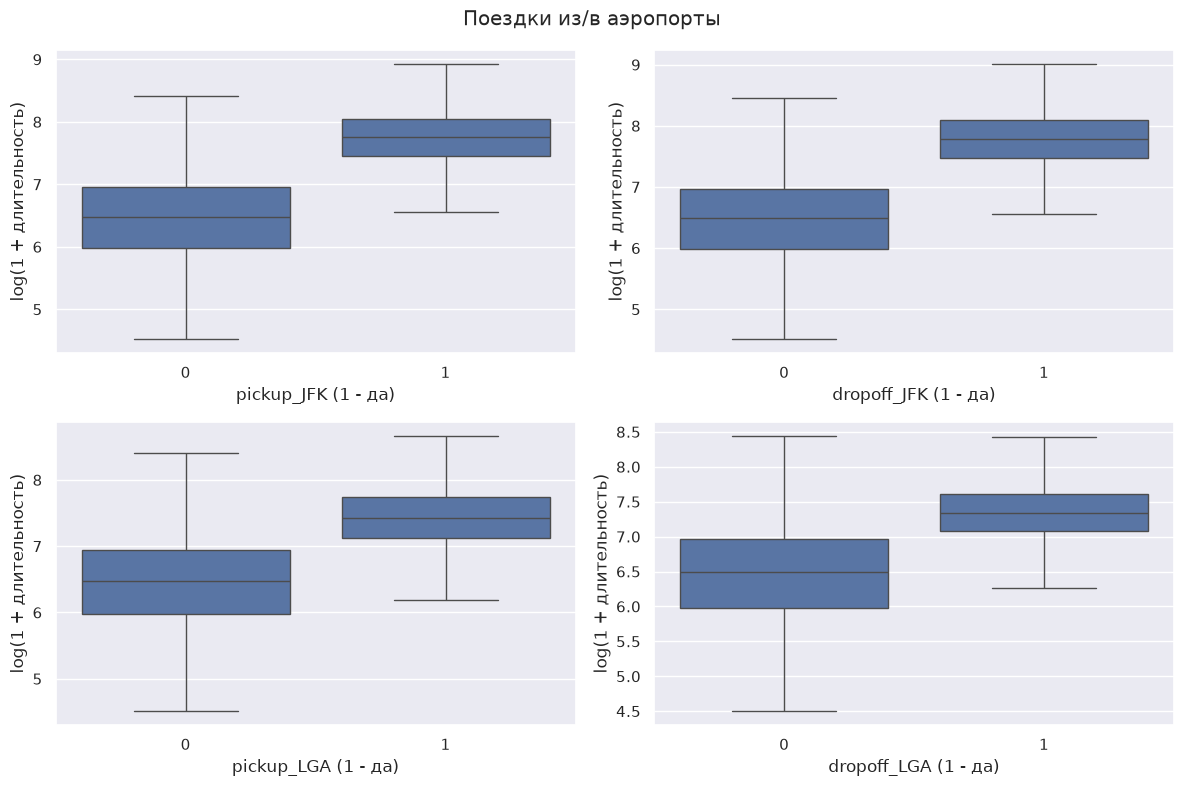

In [123]:
fig,axes = plt.subplots(2,2,figsize=(12,8))
for col,ax in zip(airport_cols,axes.flat):
    sns.boxplot(data=train,x=col,y=TARGET,showfliers=False,ax=ax)
    ax.set(xlabel=col+' (1 - да)',ylabel='log(1 + длительность)')
plt.suptitle('Поездки из/в аэропорты'); plt.tight_layout(); plt.show()

**Вопрос**: судя по графикам, как вы думаете, хорошими ли получились эти признаки?

**Ответ** У аэропортовых поездок распределения смещены к большей длительности: они часто связывают удалённые районы с Манхэттеном (?)

Дать о "хорошести" однозначный ответ не могу, тут надо исследовать

<img src="https://www.dropbox.com/s/xson9nukz5hba7c/map.png?raw=1" align="right" width="20%" style="margin-left: 20px; margin-bottom: 20px">

**Задание 9**. Сейчас мы почти что не используем сами значения координат. На это есть несколько причин: по отдельности рассматривать широту и долготу не имеет особого смысла, стоит рассматривать их вместе. Во-вторых, понятно, что зависимость между нашим таргетом и координатами не линейная. Чтобы как-то использовать координаты, можно прибегнуть к следующему трюку: обрамим область с наибольшим количеством поездок прямоугольником (как на рисунке). Разобьем этот прямоугольник на ячейки. Каждой точке сопоставим номер ее ячейки, а тем точкам, что не попали ни в одну из ячеек, сопоставим значение -1.

Напишите трансформер, который сначала разбивает показанную на рисунке область на ячейки, а затем создает два признака: номер ячейки, в которой началась поездка, и номер ячейки, в которой закончилась поездка. Количество строк и столбцов выберите самостоятельно.

Обратите внимание, что все вычисления должны быть векторизованными, трансформер не должен модифицировать передаваемую ему выборку inplace, а все необходимые статистики, если они вдруг нужны - подсказка ;), нужно считать только по обучающей выборке в методе `fit`. То есть обязательно должны быть методы `fit` и `transform`.

Еще подсказка: возможно, будет удобно воспользоваться методом `np.searchsorted` и `np.where`.
 

In [124]:
class GeoGrid(BaseEstimator, TransformerMixin):
    def __init__(self, rows=10, cols=10):
        self.rows, self.cols = rows, cols
    def fit(self, X, y=None):
        # прямоугольник Манхэттена
        self.lat_edges_ = np.linspace(40.70,40.84,self.rows+1)
        self.lon_edges_ = np.linspace(-74.025,-73.90,self.cols+1)
        return self
    def transform(self, X):
        out = X.copy()
        for end in ['pickup','dropoff']:
            lat, lon = X[end+'_latitude'].to_numpy(), X[end+'_longitude'].to_numpy()
            row = np.searchsorted(self.lat_edges_,lat,side='right')-1
            col = np.searchsorted(self.lon_edges_,lon,side='right')-1
            inside = (lat>=self.lat_edges_[0]) & (lat<=self.lat_edges_[-1]) & (lon>=self.lon_edges_[0]) & (lon<=self.lon_edges_[-1])
            out[end+'_cell'] = np.where(inside,np.minimum(row,self.rows-1)*self.cols+np.minimum(col,self.cols-1),-1)
        return out
probe = pd.DataFrame({'pickup_latitude':[40.70,40.84,0.], 'pickup_longitude':[-74.025,-73.90,0.], 'dropoff_latitude':[40.70,40.84,0.], 'dropoff_longitude':[-74.025,-73.90,0.]})
before = probe.copy(deep=True)
grid = GeoGrid().fit(train)
assert grid.transform(probe).pickup_cell.tolist() == [0,99,-1]
pd.testing.assert_frame_equal(probe,before)

**Задание 10**. Обучите `Ridge`-регрессию со стандартными параметрами на признаках, которые мы выделили к текущему моменту. Категориальные признаки закодируйте через one-hot-кодирование, числовые признаки отмасштабируйте. Будет здорово, если вы воспользуетесь `Pipeline` из `sklearn`.

In [125]:
geo_cat = time_cat+['traffic','free_roads']+airport_cols+['pickup_cell','dropoff_cell']
geo_num = time_num+['log_haversine']
def geo_model(estimator=None, rare=None):
    return Pipeline([('grid',GeoGrid()),('regression',make_model(geo_cat,geo_num,estimator,rare))])
geo = geo_model().fit(train,train[TARGET])
_ = report('Часть 2: география',geo,train,test)

,этап,train RMSE,test RMSE
0,Константа (среднее train),0.79607,0.79503
1,Часть 1: время,0.78905,0.78813
2,Часть 2: география,0.51217,0.51356


## Часть 3. Изучаем оставшиеся признаки (0.5 балла)

**Задание 11**. У нас осталось еще 3 признака, которые мы не исследовали: `vendor_id`, `passenger_count` и `store_and_fwd_flag`.

**Вопрос**: Подумайте, почему каждый из этих признаков может быть потенциально полезным.

**Ответ** Поставщик может отражать особенности регистрации и состав автопарка. пассажиры - тип поездки и посадки. store-and-forward - режим передачи записей и связанные условия связи

Посчитайте, сколько есть уникальных значений у каждого из этих признаков:

In [126]:
extra_cols = ['vendor_id','passenger_count','store_and_fwd_flag']
display(train[extra_cols].nunique().rename('уникальных значений').to_frame())

,уникальных значений
vendor_id,2
passenger_count,10
store_and_fwd_flag,2


Постройте "ящики с усами" распределений логарифма времени поездки в зависимости от значений каждого из признаков

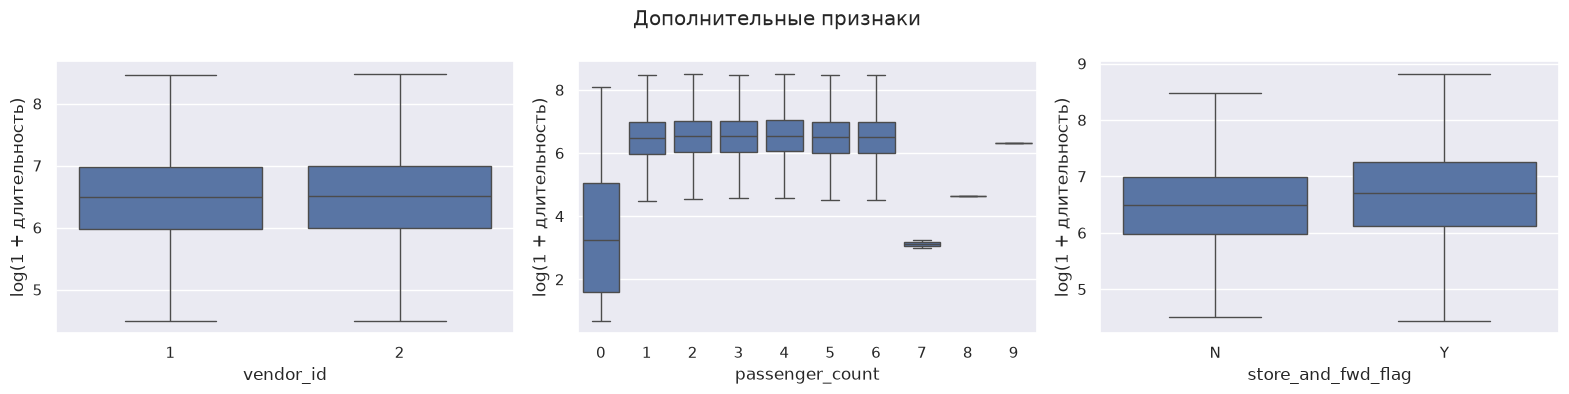

In [127]:
fig,axes = plt.subplots(1,3,figsize=(16,4))
for col,ax in zip(extra_cols,axes):
    sns.boxplot(data=train,x=col,y=TARGET,showfliers=False,ax=ax)
    ax.set_ylabel('log(1 + длительность)')
plt.suptitle('Дополнительные признаки'); plt.tight_layout(); plt.show()

Переведите признаки `vendor_id` и `store_and_fwd_flag` в значения $\{0;1\}$

In [128]:
for data in [train,test]:
    data['vendor_id'] = data.vendor_id.map({1:0,2:1})
    data['store_and_fwd_flag'] = data.store_and_fwd_flag.map({'N':0,'Y':1})
    assert data[['vendor_id','store_and_fwd_flag']].notna().all().all()

**Вопрос**: Основываясь на графиках выше, как вы думаете, будут ли эти признаки сильными?

**Ответ** Распределения сильно перекрываются, поэтому сильного эффекта не ожидаю. Небольшое улучшение возможно в сочетании с географией и временем. Редкие большие значения passenger_count особенно ненадёжны

**Задание 12**. Проверьте свои предположения, обучив модель в том числе и на этих трех признаках. Обучайте `Ridge`-регрессию со стандартными параметрами. Категориальные признаки закодируйте one-hot-кодированием, а численные отмасштабируйте.

In [129]:
all_cat = geo_cat+extra_cols
all_num = geo_num
def full_model(estimator=None, rare=None, routes=False):
    steps = [('grid',GeoGrid())]
    if routes: steps.append(('routes',FrequentRoutes()))
    steps.append(('regression',make_model(all_cat+(['route'] if routes else []),all_num,estimator,rare)))
    return Pipeline(steps)
full = full_model().fit(train,train[TARGET])
_ = report('Часть 3: дополнительные признаки',full,train,test)

previous_rmse = rmse(test[TARGET], geo.predict(test))
current_rmse = rmse(test[TARGET], full.predict(test))
delta = current_rmse - previous_rmse

print(
    f'RMSE до добавления признаков: {previous_rmse:.6f}\n'
    f'RMSE после: {current_rmse:.6f}\n'
    f'Изменение: {delta:+.6f}'
)

,этап,train RMSE,test RMSE
0,Константа (среднее train),0.79607,0.79503
1,Часть 1: время,0.78905,0.78813
2,Часть 2: география,0.51217,0.51356
3,Часть 3: дополнительные признаки,0.51180,0.51322


RMSE до добавления признаков: 0.513555
RMSE после: 0.513223
Изменение: -0.000333


Если признаки не дали какого-то ощутимого улучшения метрики, их можно выбросить из данных.

**Коммент**: Ну кажется как выше писал не дали

## Часть 4. Улучшаем модель (1.5 балла)

**Задание 13**. В наших данных есть нетипичные объекты: с аномально маленьким временем поездки, с очень большим пройденным расстоянием или очень большими остатками регрессии. В этом задании предлагается исключить такие объекты из обучающей выборки. Для этого нарисуйте гистограммы распределения упомянутых выше величин, выберите объекты, которые можно назвать выбросами, и очистите обучающую выборку от них. Нужно руководствоваться не только статистикой, но и здравым смыслом.

Отметим, что хотя эти объекты и выглядят как выбросы, в тестовой выборке тоже скорее всего будут объекты с такими же странными значениями целевой переменной и/или признаков. Поэтому, возможно, чистка обучающей выборки приведёт к ухудшению качества на тесте. Тем не менее, всё равно лучше удалять выбросы из обучения, чтобы модель получалась более разумной и интерпретируемой.

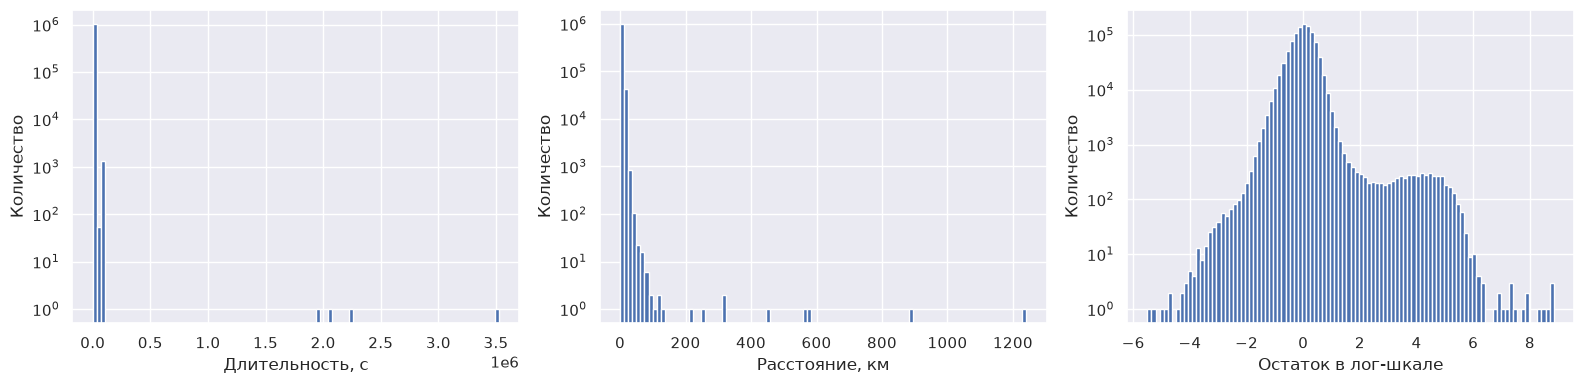

In [130]:
duration = np.expm1(train[TARGET])
residual = train[TARGET]-full.predict(train)
fig,axes = plt.subplots(1,3,figsize=(16,4))
for values,label,ax in zip([duration,train.haversine,residual],['Длительность, с','Расстояние, км','Остаток в лог-шкале'],axes):
    ax.hist(values,bins=100); ax.set(xlabel=label,ylabel='Количество',yscale='log')
plt.tight_layout(); plt.show()
def clean_training(data):
    duration = np.expm1(data[TARGET])
    physical = duration.between(30,4*3600) & data.haversine.between(.05,100)
    preliminary = full_model().fit(data.loc[physical],data.loc[physical,TARGET])
    residual = data[TARGET]-preliminary.predict(data)
    limit = residual.loc[physical].abs().quantile(.995)
    return data.loc[physical & (residual.abs()<=limit)].copy(), limit
clean, residual_limit = clean_training(train)

Сейчас у нас очень много категориальных признаков. В категориальных признаках могут содержаться редкие категории, обычно это плохо: модель сильно переобучается на таких примерах. Попробуйте объединить редкие категории в одну. Естественно, делать это нужно только для действительно редких категорий.

In [131]:
RARE = 100

Обучите модель на очищенных данных и посчитайте качество на тестовой выборке.

In [132]:
clean_model = full_model(rare=RARE).fit(clean,clean[TARGET])
_ = report('Часть 4: очистка и редкие категории',clean_model,clean,test)

,этап,train RMSE,test RMSE
0,Константа (среднее train),0.79607,0.79503
1,Часть 1: время,0.78905,0.78813
2,Часть 2: география,0.51217,0.51356
3,Часть 3: дополнительные признаки,0.51180,0.51322
4,Часть 4: очистка и редкие категории,0.36703,0.55836


**Задание 14**. После OneHot-кодирования количество признаков в нашем датасете сильно возрастает. Посчитайте количество признаков до и после кодирования категориальных признаков.

In [133]:
encoded = clean_model[:-1].transform(clean.head())
prep = clean_model.named_steps['regression'].named_steps['preprocess']
print('До кодирования:',len(all_cat+all_num))
print('После кодирования:',prep.transform(encoded).shape[1])

До кодирования: 18
После кодирования: 205


Вспомним, что Ridge (гребневая) регрессия, которую обучали выше, накладывает штраф на веса в виде квадрата Евклидовой нормы. То есть при неотрицательном коэффициенте регуляризации $\alpha$ решением задачи регрессии будет:

$$\mathbf{w}^{*}_{ridge} = \arg\min_{\mathbf{w}} \Big\{ \lVert X\mathbf{w} - \mathbf{y}\rVert_2^2
+ \alpha \lVert \mathbf{w} \rVert_2^2 \Big\} = \arg\min_{\mathbf{w}} \left\{ \sum_{i=1}^n\left(y_i - w_0 - \sum_{j=1}^pw_j\cdot x_{ij}\right)^2
+ \alpha \sum_{j=1}^pw_j^2 \right\}.$$

Мы можем рассматривать и другие нормы для штрафа. Если возьмем норму 1, то получится Lasso регрессия, аналогично при $\alpha \geq 0$:

$$\mathbf{w}^{*}_{lasso} = \arg\min_{\mathbf{w}} \Big\{ \lVert X\mathbf{w} - \mathbf{y}\rVert_2^2
+ \alpha \lVert \mathbf{w} \rVert_1 \Big\}= \arg\min_{\mathbf{w}} \left\{ \sum_{i=1}^n\left(y_i - w_0 - \sum_{j=1}^pw_j\cdot x_{ij}\right)^2
+ \alpha \sum_{j=1}^p|w_j| \right\}.$$

Ниже представлена картинка, на которой в общих чертах иллюстрируется работа штрафов (частный кейс с двумя обучаемыми весами). 

<center>
<img src="https://miro.medium.com/v2/resize:fit:1400/1*Tyu8vrwWsm0qJ4BhrSdAFA.png" width="50%" align="center">
</center>

**Вопрос**: почему регуляризация свободного коэффициента $w_0$ может быть плохой идеей?

Попробуйте обучить не `Ridge`-, а `Lasso`-регрессию. Какой метод лучше?

**Ответ** Штраф на $w_0$ притягивал бы базовый уровень предсказания к нулю и сделал решение зависимым от выбора начала отсчёта таргета. Ridge распределяет веса между коррелирующими признаками, Lasso может занулять их

In [134]:
lasso_default = full_model(Lasso(max_iter=10000,tol=1e-4,selection='random',random_state=SEED),RARE).fit(clean,clean[TARGET])
_ = report('Часть 4: Lasso alpha=1',lasso_default,clean,test)

,этап,train RMSE,test RMSE
0,Константа (среднее train),0.79607,0.79503
1,Часть 1: время,0.78905,0.78813
2,Часть 2: география,0.51217,0.51356
3,Часть 3: дополнительные признаки,0.51180,0.51322
4,Часть 4: очистка и редкие категории,0.36703,0.55836
5,Часть 4: Lasso alpha=1,0.72990,0.79510


Разбейте обучающую выборку на обучающую и валидационную в отношении 8:2. По валидационной выборке подберите оптимальные значения параметра регуляризации (по логарифмической сетке) для `Ridge` и `Lasso`, на тестовой выборке измерьте качество лучшей полученной модели.

Ridge alpha=0.01: valid RMSE=0.54851
Ridge alpha=0.0316228: valid RMSE=0.54853
Ridge alpha=0.1: valid RMSE=0.54851
Ridge alpha=0.316228: valid RMSE=0.54852
Ridge alpha=1: valid RMSE=0.54851
Ridge alpha=3.16228: valid RMSE=0.54850
Ridge alpha=10: valid RMSE=0.54849
Ridge alpha=31.6228: valid RMSE=0.54844
Ridge alpha=100: valid RMSE=0.54831
Ridge alpha=316.228: valid RMSE=0.54795
Ridge alpha=1000: valid RMSE=0.54704
Ridge alpha=3162.28: valid RMSE=0.54491
Ridge alpha=10000: valid RMSE=0.54058
Ridge alpha=31622.8: valid RMSE=0.53332
Ridge alpha=100000: valid RMSE=0.52454
Ridge alpha=316228: valid RMSE=0.52969
Ridge alpha=1e+06: valid RMSE=0.59215
Ridge alpha=3.16228e+06: valid RMSE=0.69064
Ridge alpha=1e+07: valid RMSE=0.75434
Lasso alpha=1: valid RMSE=0.79420
Lasso alpha=0.316228: valid RMSE=0.59498
Lasso alpha=0.1: valid RMSE=0.54572
Lasso alpha=0.0316228: valid RMSE=0.54412
Lasso alpha=0.01: valid RMSE=0.54645
Lasso alpha=0.00316228: valid RMSE=0.54359
Lasso alpha=0.001: valid RMSE=0.5

,model,alpha,train RMSE,valid RMSE,zeros,features
24,Lasso,0.003162,0.382963,0.543593,177,204
14,Ridge,100000.000000,0.394423,0.524536,0,204


,этап,train RMSE,test RMSE
0,Константа (среднее train),0.79607,0.79503
1,Часть 1: время,0.78905,0.78813
2,Часть 2: география,0.51217,0.51356
3,Часть 3: дополнительные признаки,0.51180,0.51322
4,Часть 4: очистка и редкие категории,0.36703,0.55836
5,Часть 4: Lasso alpha=1,0.72990,0.79510
6,Часть 4: выбранная по validation модель,0.38998,0.53461


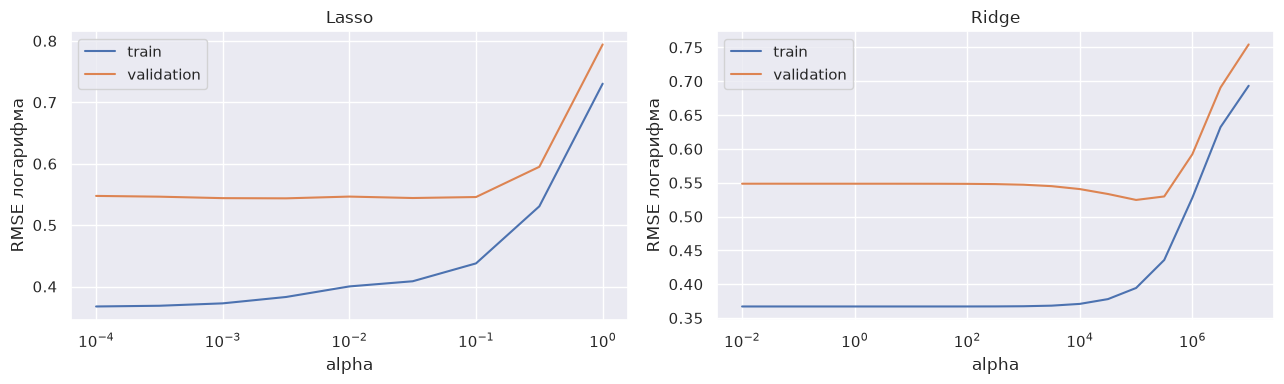

In [135]:
inner_train, valid = train_test_split(train,test_size=.2,random_state=SEED)
inner_clean, _ = clean_training(inner_train)

feature_pipeline = Pipeline([('grid',GeoGrid()),('preprocess',make_model(all_cat,all_num,min_frequency=RARE).named_steps['preprocess'])])
X_fit = feature_pipeline.fit_transform(inner_clean,inner_clean[TARGET])
X_valid = feature_pipeline.transform(valid)
y_fit, y_valid = inner_clean[TARGET].to_numpy(), valid[TARGET].to_numpy()
search_rows = []
for kind, alphas in [('Ridge',np.logspace(-2,7,19)),('Lasso',np.logspace(0,-4,9))]:
    model = Ridge() if kind=='Ridge' else Lasso(max_iter=20000,tol=1e-4,selection='random',random_state=SEED,warm_start=True)
    for alpha in alphas:
        model.set_params(alpha=alpha)
        model.fit(X_fit,y_fit)
        if kind=='Lasso': assert model.n_iter_ < model.max_iter, 'Lasso не сошлась: увеличьте max_iter'
        search_rows.append({'model':kind,'alpha':alpha,'train RMSE':rmse(y_fit,model.predict(X_fit)), 'valid RMSE':rmse(y_valid,model.predict(X_valid)), 'zeros':int(np.count_nonzero(np.abs(model.coef_)<=1e-8)), 'features':len(model.coef_)})
        print(f'{kind} alpha={alpha:.6g}: valid RMSE={search_rows[-1]["valid RMSE"]:.5f}',flush=True)
search = pd.DataFrame(search_rows)
best_rows = search.loc[search.groupby('model')['valid RMSE'].idxmin()]
display(best_rows)
best = best_rows.loc[best_rows['valid RMSE'].idxmin()]
def chosen_estimator():
    return Ridge(alpha=float(best.alpha)) if best.model=='Ridge' else Lasso(alpha=float(best.alpha),max_iter=20000,tol=1e-4,selection='random',random_state=SEED)
tuned = full_model(chosen_estimator(),RARE).fit(clean,clean[TARGET])
_ = report('Часть 4: выбранная по validation модель',tuned,clean,test)
fig,axes=plt.subplots(1,2,figsize=(13,4))
for (kind,group),ax in zip(search.groupby('model'),axes):
    ax.semilogx(group.alpha,group['train RMSE'],label='train')
    ax.semilogx(group.alpha,group['valid RMSE'],label='validation')
    ax.set(title=kind,xlabel='alpha',ylabel='RMSE логарифма'); ax.legend()
plt.tight_layout(); plt.show()

Для каждого перебранного `alpha` для Lasso посчитайте количество нулевых весов в модели и нарисуйте график зависимости его от `alpha`. Как сильно придётся потерять в качестве, если мы хотим с помощью Lasso избавиться хотя бы от половины признаков?

,Lasso с ≥50% нулей
model,Lasso
alpha,0.003162
train RMSE,0.382963
valid RMSE,0.543593
zeros,177
features,204
zero_fraction,0.867647


Лучшая Lasso: alpha=0.00316228, validation RMSE=0.54359
Потеря RMSE: 0.00000 (0.00%)


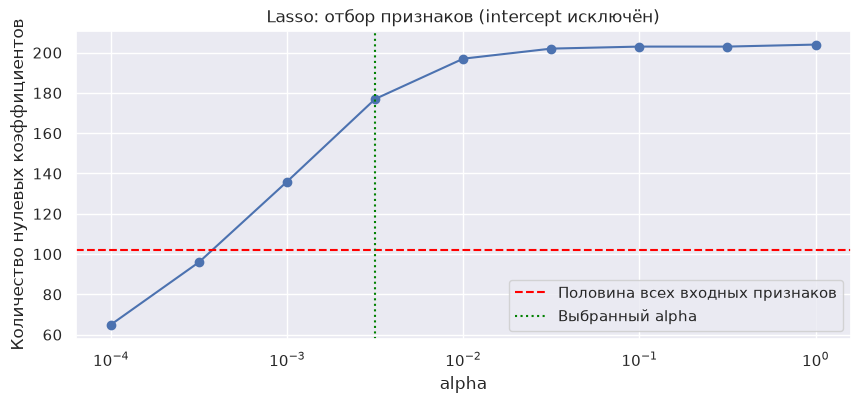

In [136]:
lasso_search = search.loc[search.model=='Lasso'].copy()
lasso_search['zero_fraction'] = lasso_search.zeros/lasso_search.features
eligible = lasso_search.loc[lasso_search.zero_fraction>=.5]
assert not eligible.empty, 'Расширьте сетку alpha вверх: половина коэффициентов ещё не обнулена'
sparse_best = eligible.loc[eligible['valid RMSE'].idxmin()]
lasso_best = lasso_search.loc[lasso_search['valid RMSE'].idxmin()]
loss = sparse_best['valid RMSE']-lasso_best['valid RMSE']
display(sparse_best.to_frame('Lasso с ≥50% нулей'))
print(f'Лучшая Lasso: alpha={lasso_best.alpha:.6g}, validation RMSE={lasso_best["valid RMSE"]:.5f}')
print(f'Потеря RMSE: {loss:.5f} ({loss/lasso_best["valid RMSE"]:.2%})')
fig,ax=plt.subplots(figsize=(10,4))
ax.semilogx(lasso_search.alpha,lasso_search.zeros,marker='o')
ax.axhline(X_fit.shape[1]/2,color='red',linestyle='--',label='Половина всех входных признаков')
ax.axvline(sparse_best.alpha,color='green',linestyle=':',label='Выбранный alpha')
ax.set(xlabel='alpha',ylabel='Количество нулевых коэффициентов',title='Lasso: отбор признаков (intercept исключён)'); ax.legend(); plt.show()

<img src="https://www.dropbox.com/s/wp4jj0599np17lh/map_direction.png?raw=1" width="20%" align="right" style="margin-left: 20px">

**Задание 15**. Часто бывает полезным использовать взаимодействия признаков (feature interactions), то есть строить новые признаки на основе уже существующих. Выше мы разбили карту Манхэттена на ячейки и придумали признаки "из какой ячейки началась поездка" и "в какой ячейке закончилась поездка".

Давайте попробуем сделать следующее: посчитаем, сколько раз встречается каждая возможная пара этих признаков в нашем датасете и выберем 100 самых частых пар. Закодируем поездки с этими частыми парами как категориальный признак, остальным объектам припишем -1. Получается, что мы закодировали, откуда и куда должно было ехать такси.

**Вопрос**: Почему такой признак потенциально полезный? Почему линейная модель не может самостоятельно "вытащить" эту информацию, ведь у нее в распоряжении есть признаки "из какой ячейки началась поездка" и "в какой ячейке закончилась поездка"?

**Ответ** Линейная модель с отдельными ячейками складывает эффект места отправления и назначения. Она не может назначить отдельный эффект конкретной паре, например маршруту через мост

In [137]:
class FrequentRoutes(BaseEstimator,TransformerMixin):
    def __init__(self, top_n=100): self.top_n=top_n
    def fit(self,X,y=None):
        pairs = X[['pickup_cell','dropoff_cell']]
        self.routes_ = pairs.value_counts().head(self.top_n).index
        return self
    def transform(self,X):
        out=X.copy()
        pairs=pd.MultiIndex.from_frame(X[['pickup_cell','dropoff_cell']])
        out['route']=self.routes_.get_indexer(pairs)
        return out
route_probe=pd.DataFrame({'pickup_cell':[1,1,2,-1], 'dropoff_cell':[2,2,1,0]})
routes_check=FrequentRoutes(top_n=1).fit(route_probe)
assert routes_check.transform(route_probe).route.tolist()==[0,0,-1,-1]
assert routes_check.transform(pd.DataFrame({'pickup_cell':[9],'dropoff_cell':[9]})).route.iloc[0]==-1

Заново обучите модель (`Ridge`, если она дала более высокое качество в предыдущих экспериментах, и `Lasso` иначе) на новых данных и посчитайте качество на тестовой выборке

,этап,train RMSE,test RMSE
0,Константа (среднее train),0.79607,0.79503
1,Часть 1: время,0.78905,0.78813
2,Часть 2: география,0.51217,0.51356
3,Часть 3: дополнительные признаки,0.51180,0.51322
4,Часть 4: очистка и редкие категории,0.36703,0.55836
5,Часть 4: Lasso alpha=1,0.72990,0.79510
6,Часть 4: выбранная по validation модель,0.38998,0.53461
7,Часть 4: взаимодействия маршрутов,0.38917,0.53244


Выбранная модель: Ridge, alpha=100000
Отрицательных лог-прогнозов: 0
RMSLE физически допустимых прогнозов: 0.53244
Размер теста: 437594


,этап,train RMSE,test RMSE,"выигрыш против константы, %"
0,Константа (среднее train),0.79607,0.79503,0.00000
1,Часть 1: время,0.78905,0.78813,0.86742
2,Часть 2: география,0.51217,0.51356,35.40403
3,Часть 3: дополнительные признаки,0.51180,0.51322,35.44588
4,Часть 4: очистка и редкие категории,0.36703,0.55836,29.76780
5,Часть 4: Lasso alpha=1,0.72990,0.79510,-0.00882
6,Часть 4: выбранная по validation модель,0.38998,0.53461,32.75590
7,Часть 4: взаимодействия маршрутов,0.38917,0.53244,33.02827


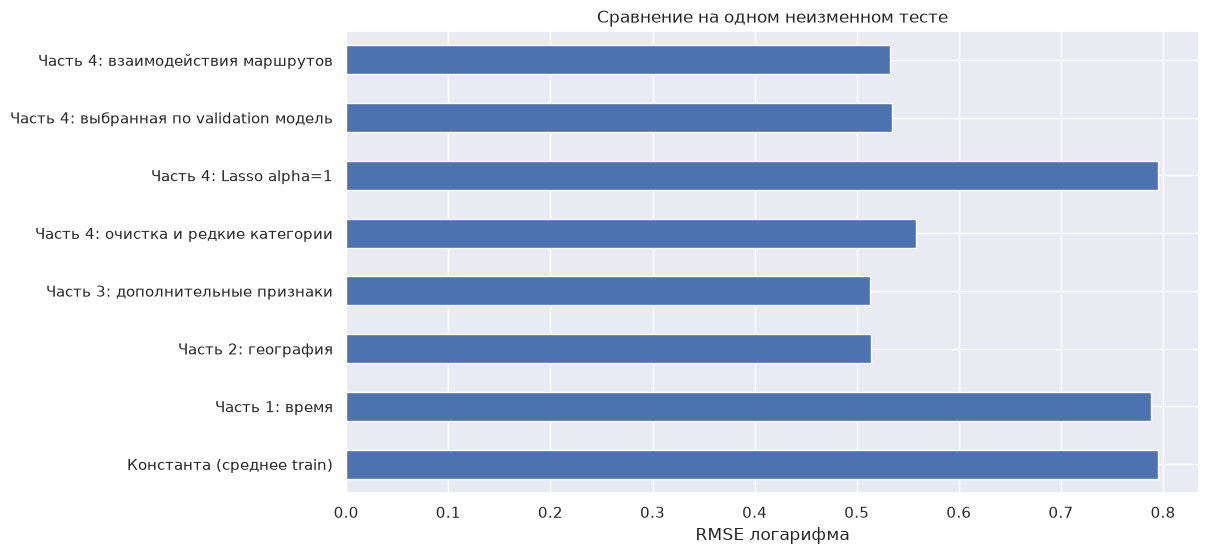

In [139]:
route_model = full_model(chosen_estimator(),RARE,routes=True).fit(clean,clean[TARGET])
final_prediction = report('Часть 4: взаимодействия маршрутов',route_model,clean,test)
print(f'Выбранная модель: {best.model}, alpha={best.alpha:.6g}')
print(f'Отрицательных лог-прогнозов: {(final_prediction<0).sum()}')
seconds = np.maximum(np.expm1(final_prediction),0)
print(f'RMSLE физически допустимых прогнозов: {rmse(test[TARGET],np.log1p(seconds)):.5f}')
print('Размер теста:',len(test))
assert results[2]['test RMSE'] < results[1]['test RMSE'] < results[0]['test RMSE']
assert results[-1]['test RMSE'] < results[1]['test RMSE']
assert not {'speed','trip_duration','log_trip_duration','dropoff_datetime','id'} & set(all_cat+all_num)
summary=pd.DataFrame(results)
summary['выигрыш против константы, %']=(1-summary['test RMSE']/summary.iloc[0]['test RMSE'])*100
display(summary.round(5))
summary.plot.barh(x='этап',y='test RMSE',legend=False,figsize=(11,6))
plt.xlabel('RMSE логарифма'); plt.ylabel(''); plt.title('Сравнение на одном неизменном тесте'); plt.show()

## Часть N.

Вставьте картинку, описывающую ваш опыт выполнения этого ДЗ.

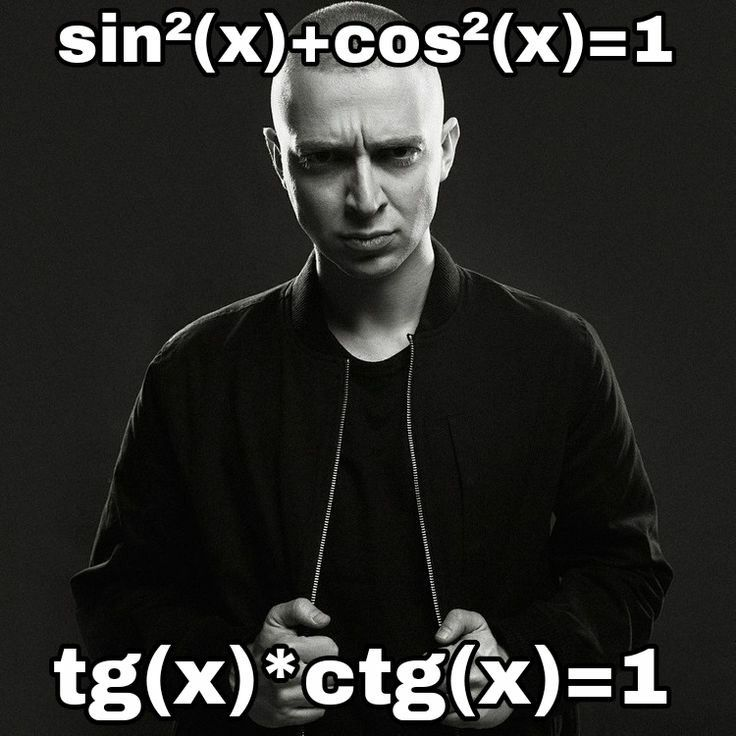

In [138]:
display(Image(filename="./assets/ott.jpg"))